In [1]:
from google.colab import files
import zipfile
import json
import os
import shutil

# Upload ZIP with rag_retrieval results
uploaded = files.upload()

# Get the actual uploaded filename
zip_filename = next(iter(uploaded))

# Remove previous extracted files
if os.path.exists("rag_output"):
    shutil.rmtree("rag_output")

# Extract the uploaded ZIP
with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall("rag_output")

# Load the JSON
with open("rag_output/rag_context.json", "r", encoding="utf-8") as f:
    rag_context = json.load(f)

print("Loaded ZIP:", zip_filename)
print("Query:", rag_context["query"])
print("Question:", rag_context["question"])

Saving rag_output.zip to rag_output (1).zip
Loaded ZIP: rag_output (1).zip
Query: A dark brown seabird with long wings and a curved beak
Question: What bird species is this, and what are its characteristics?


Selected image: rag_output/retrieved_image_1.jpg
Retrieval distance: 0.6585793495178223


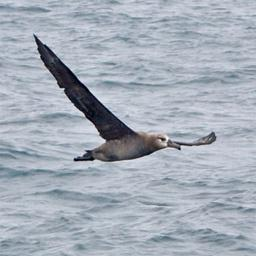

In [2]:

from pathlib import Path
from PIL import Image
from IPython.display import display

retrieved = rag_context["retrieved"]

# Get retrieved images
images = [
    item for item in retrieved["image"]
    if item.get("image_file")
]

if not images:
    raise ValueError("No retrieved images available.")

# Select the image with the smallest distance
best_image = min(
    images,
    key=lambda item: item["distance"]
)

image_path = Path("rag_output") / best_image["image_file"]

print("Selected image:", image_path)
print("Retrieval distance:", best_image["distance"])

# Display the image
image = Image.open(image_path).convert("RGB")
display(image)


In [3]:

question = rag_context["question"]
query = rag_context["query"]
retrieved = rag_context["retrieved"]

# Prepare retrieved text descriptions
text_context = "\n\n".join(
    f"Species: {item['species']}\n"
    f"Description: {item['description']}"
    for item in retrieved["text"]
)

# Prepare image metadata
image_context = "\n".join(
    f"Image {i + 1}: {item['species']}"
    for i, item in enumerate(retrieved["image"])
)

# Prepare audio metadata
audio_context = "\n".join(
    f"Audio {i + 1}: {item['species']}"
    for i, item in enumerate(retrieved["audio_projected"])
)

# Construct prompt
prompt = f"""
You are an expert ornithologist.

A bird image has been retrieved from a multimodal bird database.
Examine the provided image and answer the question.

User description:
{query}

Question:
{question}

Retrieved text descriptions from the database:
{text_context}

Other retrieved image metadata:
{image_context}

Retrieved audio metadata:
{audio_context}

Instructions:
- Identify the species and describe its characteristics.
- Identify the bird primarily from the provided image.
- Use the retrieved descriptions as supporting evidence.
- Only one image is provided for visual analysis.
- Audio references contain species metadata only.
- You have not listened to the audio recordings.
- Do not claim to have analyzed the audio recordings.
- Do not invent unsupported characteristics.
- Answer clearly and briefly.
"""

print(prompt)




You are an expert ornithologist.

A bird image has been retrieved from a multimodal bird database.
Examine the provided image and answer the question.

User description:
A dark brown seabird with long wings and a curved beak

Question:
What bird species is this, and what are its characteristics?

Retrieved text descriptions from the database:
Species: 001.Black_footed_Albatross
Description: the medium sized bird has a dark grey color, a black downward curved beak, and long wings.
the bird is dark grey brown with a thick curved bill and a flat shaped tail.
bird has brown body feathers, white breast feathers and black beak
this bird has a dark brown overall body color, with a small white patch around the base of the bill.
the bird has very long and large brown wings, as well as a black body and a long black beak.
it is a type of albatross with black wings, tail, back and beak, and has a white ring at the base of its beak.
this bird has brown plumage and a white ring at the base of its l

In [4]:
!pip install -q transformers accelerate bitsandbytes pillow

In [5]:

import torch
from transformers import (
    LlavaForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig
)

# Loading LLaVa model...
model_id = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)

model = LlavaForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=quantization_config,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(model_id)

print("LLaVA loaded successfully!")


model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

LLaVA loaded successfully!


In [6]:

import torch
from PIL import Image

# Use the image selected in the previous step (image with the smallest distance)
image = Image.open(image_path).convert("RGB")

# Create the LLaVA conversation
conversation = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": prompt}
        ]
    }
]

# Format prompt for LLaVA
formatted_prompt = processor.apply_chat_template(
    conversation,
    add_generation_prompt=True
)

# Prepare model inputs
inputs = processor(
    images=image,
    text=formatted_prompt,
    return_tensors="pt"
).to("cuda")

# Generate answer
with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=200,
        do_sample=False
    )

# Decode generated text only
answer = processor.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("\nUSER QUERY:", query)
print("SELECTED IMAGE:", image_path)
print("\nLLaVA ANSWER:")
print(answer)



USER QUERY: A dark brown seabird with long wings and a curved beak
SELECTED IMAGE: rag_output/retrieved_image_1.jpg

LLaVA ANSWER:
The bird in the image is a Black-footed Albatross. It has a dark brown body, a black downward curved beak, and long wings. The bird is mostly black with some white around its bill and has a white ring at the base of its beak. It is a large bird with a grey coloring and long beak.
